In [2]:
%pip install kagglehub --quiet

In [3]:
import os, time, copy, random
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
import torchvision.models as models

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    classification_report, confusion_matrix,
    precision_recall_fscore_support
)

SEED = 42
random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "| Torch:", torch.__version__)

Device: cuda | Torch: 2.11.0+cu130


In [4]:
import kagglehub

path = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset")
print("Path to dataset files:", path)
print(os.listdir(path))

Using Colab cache for faster access to the 'brain-tumor-mri-dataset' dataset.
Path to dataset files: /kaggle/input/brain-tumor-mri-dataset
['Training', 'Testing']


# Загрузка изображений в память
* ЦЕЛЬ: загрузить все снимки в память в виде массивов и привести к единому формату.
* IMG_SIZE=128: компромисс между скоростью и деталями (меньше - быстрее, но теряются мелкие признаки).
* .convert("RGB"): МРТ серые, но ResNet обучена на 3 каналах, поэтому серый дублируется в три канала.
* загружаю всё в память целиком: данных немного (~7200 снимков), так обучение идёт быстрее, чем чтение с диска.



In [5]:
IMG_SIZE = 128
TRAIN_DIR = os.path.join(path, "Training")
TEST_DIR  = os.path.join(path, "Testing")

classes = sorted(os.listdir(TRAIN_DIR))
print("Классы:", classes)

def load_folder(root, per_class=None):
    images, labels = [], []
    for cls in classes:
        cls_path = os.path.join(root, cls)
        if not os.path.isdir(cls_path):
            continue
        files = sorted(os.listdir(cls_path))
        if per_class is not None:
            files = files[:per_class]
        for name in files:
            try:
                # МРТ чёрно-белые привожу к 3 каналам, чтобы подошло ResNet
                img = Image.open(os.path.join(cls_path, name)).convert("RGB")
                img = img.resize((IMG_SIZE, IMG_SIZE))
            except Exception as e:
                print("skip", name, e); continue
            images.append(np.array(img))
            labels.append(cls)
    return np.array(images, dtype=np.uint8), np.array(labels)

X_train_all, y_train_all = load_folder(TRAIN_DIR, per_class=None)
X_test,      y_test      = load_folder(TEST_DIR,  per_class=None)

print("Train pool:", X_train_all.shape, "Test:", X_test.shape)

Классы: ['glioma', 'meningioma', 'notumor', 'pituitary']
Train pool: (5600, 128, 128, 3) Test: (1600, 128, 128, 3)


EDA: примеры по классам

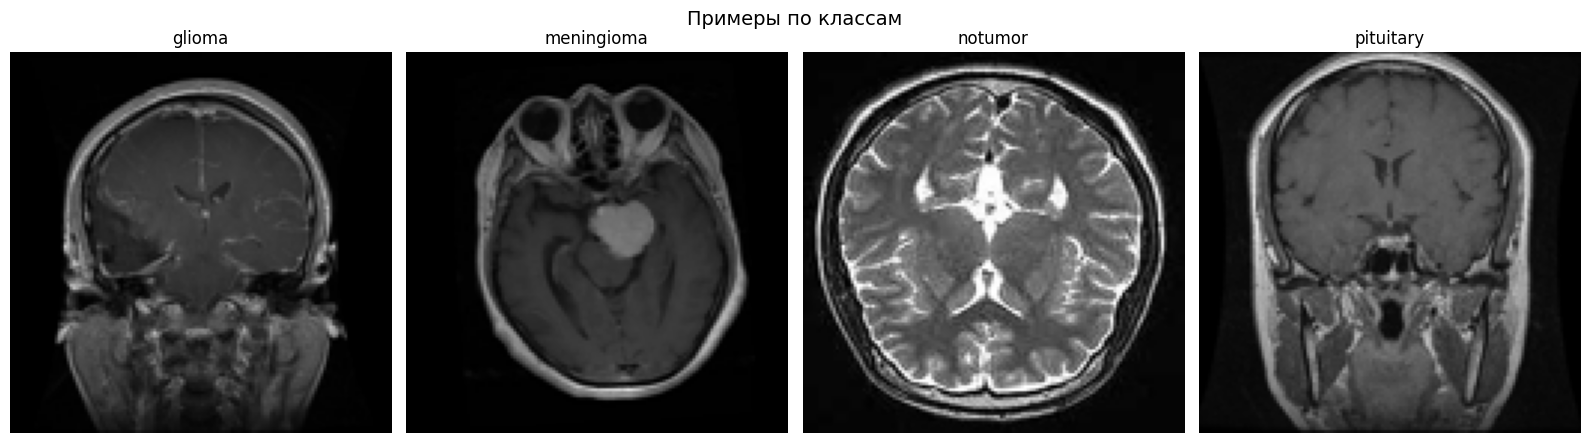

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))
for ax, cls in zip(axes.ravel(), classes):
    idx = np.where(y_train_all == cls)[0][0]
    ax.imshow(X_train_all[idx])
    ax.set_title(cls)
    ax.axis("off")
plt.suptitle("Примеры по классам", fontsize=14)
plt.tight_layout(); plt.show()

EDA: баланс классов

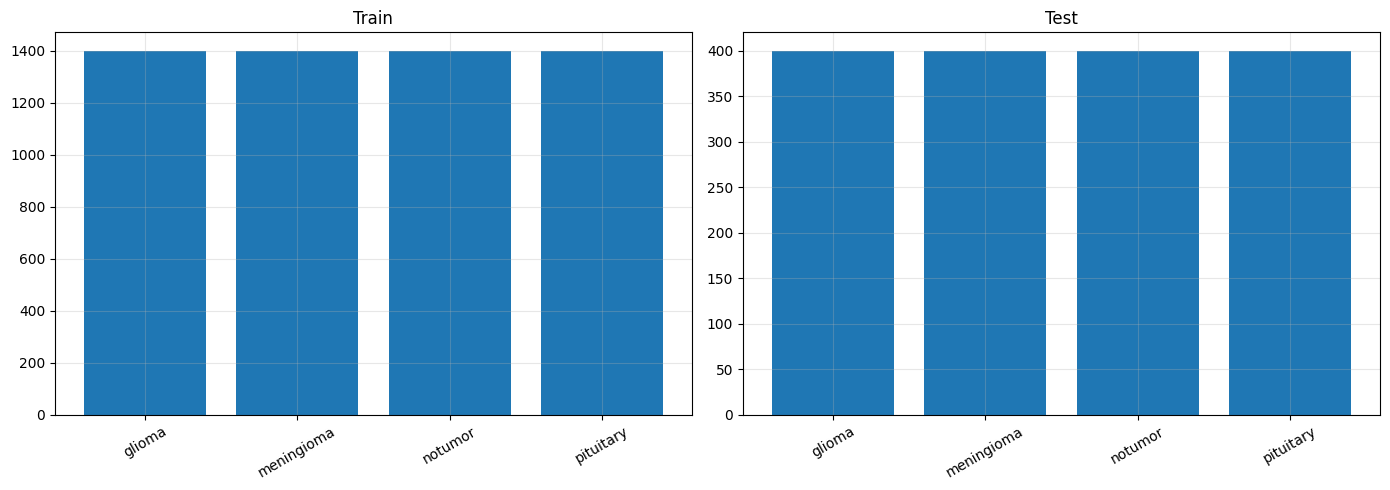

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (y_, ttl) in zip(axes, [(y_train_all, "Train"), (y_test, "Test")]):
    u, c = np.unique(y_, return_counts=True)
    ax.bar(u, c); ax.set_title(ttl); ax.tick_params(axis='x', rotation=30)
    ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Вывод:** классы сбалансированы (в test по 400 снимков каждого класса). Поэтому accuracy
является честной метрикой, и веса классов не нужны. При дисбалансе модель могла бы всегда
предсказывать самый частый класс и всё равно получать высокую accuracy.

# train/val split (разделение обучающих данных)

* ЦЕЛЬ: получить честную оценку качества и не подгонять модель под тест.
* РЕШЕНИЕ: из папки Training выделяю 20% под val. Он нужен для выбора лучшей эпохи.
* early stopping и снижения lr. Папку Testing не трогаем до самого конца.
* stratify: доли классов в train и val одинаковые, чтобы оценка по val не была перекошена.
* random_state=SEED: разбиение каждый раз одинаковое, результаты воспроизводимы.

In [8]:
le = LabelEncoder()
le.fit(classes)
class_names = list(le.classes_)
NUM_CLASSES = len(class_names)
print("Классы:", class_names)

y_train_all_enc = le.transform(y_train_all)
y_test_enc      = le.transform(y_test)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_all, y_train_all_enc,
    test_size=0.2, random_state=SEED, stratify=y_train_all_enc
)
print(f"Train: {len(X_train)}, Val: {len(X_val)}, Test: {len(X_test)}")

Классы: [np.str_('glioma'), np.str_('meningioma'), np.str_('notumor'), np.str_('pituitary')]
Train: 4480, Val: 1120, Test: 1600


# Нормализация, аугментации, Dataset, DataLoader
* ЦЕЛЬ: подготовить данные для сети.
* Нормализация: привожу пиксели к среднему 0 и разбросу 1, так сеть обучается быстрее и стабильнее.
* mean и std считаю ТОЛЬКО по train, чтобы информация из val и test не просочилась в обучение (утечка данных).
* Аугментации применяю только к train: они искусственно расширяют данные и борются с переобучением.
* В val и test случайности нет, иначе оценка была бы шумной.

In [9]:
X_train_f = X_train.astype(np.float32) / 255.0
mean = X_train_f.mean(axis=(0, 1, 2)).astype(np.float32)
std  = X_train_f.std(axis=(0, 1, 2)).astype(np.float32)
print("mean:", mean, "std:", std)
del X_train_f

train_tfms = T.Compose([
    T.ToPILImage(),
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.RandomHorizontalFlip(), # мозг примерно симметричен, отражение не меняет диагноз
    T.RandomRotation(10), # снимки делают под чуть разными углами
    T.ColorJitter(brightness=0.1, contrast=0.1), # разные аппараты дают разную яркость и контраст
    T.ToTensor(),
    T.Normalize(mean=mean, std=std),
])

eval_tfms = T.Compose([
    T.ToPILImage(),
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor(),
    T.Normalize(mean=mean, std=std),
])

class ImageDataset(Dataset):
    def __init__(self, images, labels, transform=None):
        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img = self.images[idx]
        label = int(self.labels[idx])
        if self.transform:
            img = self.transform(img)
        return img, label

BATCH_SIZE = 64 # компромисс между скоростью и стабильностью шага обучения
train_loader = DataLoader(ImageDataset(X_train, y_train, train_tfms),
                          batch_size=BATCH_SIZE, shuffle=True,  num_workers=0)
val_loader   = DataLoader(ImageDataset(X_val,   y_val,   eval_tfms),
                          batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader  = DataLoader(ImageDataset(X_test,  y_test_enc, eval_tfms),
                          batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

mean: [0.14160526 0.14160527 0.14164548] std: [0.17598583 0.17598517 0.17602508]


# SimpleCNN
* АРХИТЕКТУРА: 4 блока "свёртка -> BatchNorm -> ReLU -> MaxPool", затем 2 полносвязных слоя.
* Число каналов растёт (32 -> 64 -> 128 -> 128), а размер картинки падает (128 -> 64 -> 32 -> 16 -> 8):
* сеть переходит от простых признаков (края) к сложным (формы, структуры).
* BatchNorm стабилизирует и ускоряет обучение; ReLU добавляет нелинейность;
* MaxPool уменьшает картинку и оставляет самые сильные сигналы; Dropout борется с переобучением.
* Всего ~2.3 млн параметров: сеть небольшая, учится с нуля.

In [10]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes=4):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.bn1   = nn.BatchNorm2d(32)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2   = nn.BatchNorm2d(64)
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn3   = nn.BatchNorm2d(128)
        self.conv4 = nn.Conv2d(128, 128, kernel_size=3, padding=1)
        self.bn4   = nn.BatchNorm2d(128)

        self.pool    = nn.MaxPool2d(2, 2)
        self.relu    = nn.ReLU(inplace=True)
        self.dropout = nn.Dropout(0.5) # при обучении случайно отключает 50% нейронов, чтобы сеть не заучивала данные

        self.fc1 = nn.Linear(128 * (IMG_SIZE // 16) * (IMG_SIZE // 16), 256)
        self.fc2 = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.pool(self.relu(self.bn1(self.conv1(x))))
        x = self.pool(self.relu(self.bn2(self.conv2(x))))
        x = self.pool(self.relu(self.bn3(self.conv3(x))))
        x = self.pool(self.relu(self.bn4(self.conv4(x))))
        x = x.view(x.size(0), -1)
        x = self.dropout(self.relu(self.fc1(x)))
        return self.fc2(x)

_model = SimpleCNN(num_classes=NUM_CLASSES).to(device)
with torch.no_grad():
    print(_model(torch.randn(2, 3, IMG_SIZE, IMG_SIZE).to(device)).shape)
del _model

torch.Size([2, 4])


# Функции обучения и оценки
* train_one_epoch: один проход по train с обновлением весов.
* evaluate: проход по данным БЕЗ обновления весов (для val и test), возвращает метрики и метки для отчётов.
* fit: цикл по эпохам с тремя защитами от плохого обучения:
  1) scheduler снижает lr вдвое, если val loss не улучшается 2 эпохи;
  2) early stopping прекращает обучение, если val loss не улучшается patience эпох подряд;
  3) в конце возвращаются ЛУЧШИЕ веса (по val loss), а не последние: последние могут быть хуже.

In [11]:
def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        out = model(xb)
        loss = criterion(out, yb)
        loss.backward(); optimizer.step()
        running_loss += loss.item() * xb.size(0)
        correct += (out.argmax(1) == yb).sum().item()
        total += xb.size(0)
    return running_loss / total, correct / total

@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    y_true, y_pred = [], []
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        out = model(xb)
        loss = criterion(out, yb)
        running_loss += loss.item() * xb.size(0)
        pred = out.argmax(1)
        correct += (pred == yb).sum().item()
        total += xb.size(0)
        y_true.extend(yb.cpu().numpy())
        y_pred.extend(pred.cpu().numpy())
    return (running_loss / total, correct / total,
            np.array(y_true), np.array(y_pred))

def fit(model, train_loader, val_loader, epochs=15, lr=1e-3,
        weight_decay=0.0, patience=5, title="Model"):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=lr, weight_decay=weight_decay
    )
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=0.5, patience=2
    )
    history = {"train_loss": [], "val_loss": [],
               "train_acc": [],  "val_acc": [], "time": []}
    best_val_loss, best_state, no_improve = float("inf"), None, 0

    for epoch in range(epochs):
        t0 = time.time()
        tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer)
        val_loss, val_acc, _, _ = evaluate(model, val_loader, criterion)
        scheduler.step(val_loss)
        dt = time.time() - t0

        history["train_loss"].append(tr_loss); history["val_loss"].append(val_loss)
        history["train_acc"].append(tr_acc);   history["val_acc"].append(val_acc)
        history["time"].append(dt)

        print(f"[{title}] epoch {epoch+1:02d}/{epochs} | "
              f"train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
              f"val loss {val_loss:.4f} acc {val_acc:.4f} | {dt:.1f}s")

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            no_improve = 0
        else:
            no_improve += 1
            if no_improve >= patience:
                print(f"Early stopping на эпохе {epoch+1}")
                break

    model.load_state_dict(best_state)
    return history

# Обучение SimpleCNN
* lr=1e-3: сеть учится с нуля, поэтому беру более крупный шаг.
* weight_decay=1e-5: небольшой L2-штраф за большие веса (ещё одна защита от переобучения).
* patience=4: ждe 4 эпохи без улучшения, чтобы не остановиться из-за случайного скачка val loss.

In [13]:
cnn_model = SimpleCNN(num_classes=NUM_CLASSES).to(device)
hist_cnn = fit(cnn_model, train_loader, val_loader,
               epochs=15, lr=1e-3, weight_decay=1e-5,
               patience=4, title="SimpleCNN")

[SimpleCNN] epoch 01/15 | train loss 1.1528 acc 0.5873 | val loss 0.7366 acc 0.6714 | 11.9s
[SimpleCNN] epoch 02/15 | train loss 0.6222 acc 0.7487 | val loss 0.5147 acc 0.7982 | 9.4s
[SimpleCNN] epoch 03/15 | train loss 0.5391 acc 0.7848 | val loss 0.6095 acc 0.7634 | 9.5s
[SimpleCNN] epoch 04/15 | train loss 0.4749 acc 0.8125 | val loss 0.4877 acc 0.7902 | 9.5s
[SimpleCNN] epoch 05/15 | train loss 0.4207 acc 0.8328 | val loss 0.6494 acc 0.7027 | 9.4s
[SimpleCNN] epoch 06/15 | train loss 0.4149 acc 0.8328 | val loss 0.3642 acc 0.8696 | 9.4s
[SimpleCNN] epoch 07/15 | train loss 0.3824 acc 0.8507 | val loss 0.3357 acc 0.8589 | 9.5s
[SimpleCNN] epoch 08/15 | train loss 0.3397 acc 0.8658 | val loss 0.2719 acc 0.9018 | 9.5s
[SimpleCNN] epoch 09/15 | train loss 0.3143 acc 0.8739 | val loss 0.2453 acc 0.9062 | 9.5s
[SimpleCNN] epoch 10/15 | train loss 0.2776 acc 0.8949 | val loss 0.2490 acc 0.8964 | 9.5s
[SimpleCNN] epoch 11/15 | train loss 0.2790 acc 0.8953 | val loss 0.2685 acc 0.9062 | 9.5

# ResNet18 и обучение
* TRANSFER LEARNING: беру ResNet18 с весами, обученными на ImageNet (1.2 млн картинок).
* Базовые признаки (края, текстуры, формы) универсальны, поэтому сеть адаптируется быстрее и точнее.
* Заменяю только последний слой fc: там было 1000 классов ImageNet, а у нас 4.
* freeze_backbone=False: дообучаю всю сеть, а не только голову, потому что МРТ сильно отличается от обычных фото.
* lr=3e-4 меньше, чем у SimpleCNN: веса уже хорошие, их нужно лишь аккуратно подправить.
* patience=3 меньше, потому что ResNet сходится быстро.

In [14]:
def build_resnet18(num_classes=4, freeze_backbone=False):
    model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
    if freeze_backbone:
        for p in model.parameters():
            p.requires_grad = False
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model

resnet_model = build_resnet18(num_classes=NUM_CLASSES, freeze_backbone=False).to(device)
hist_resnet = fit(resnet_model, train_loader, val_loader,
                  epochs=10, lr=3e-4, weight_decay=1e-4,
                  patience=3, title="ResNet18")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 160MB/s]


[ResNet18] epoch 01/10 | train loss 0.3028 acc 0.8897 | val loss 0.1331 acc 0.9509 | 11.1s
[ResNet18] epoch 02/10 | train loss 0.1119 acc 0.9589 | val loss 0.1323 acc 0.9571 | 11.1s
[ResNet18] epoch 03/10 | train loss 0.0836 acc 0.9730 | val loss 0.1802 acc 0.9330 | 12.9s
[ResNet18] epoch 04/10 | train loss 0.0610 acc 0.9781 | val loss 0.1190 acc 0.9607 | 10.9s
[ResNet18] epoch 05/10 | train loss 0.0539 acc 0.9786 | val loss 0.2090 acc 0.9366 | 10.8s
[ResNet18] epoch 06/10 | train loss 0.0595 acc 0.9804 | val loss 0.0896 acc 0.9679 | 10.9s
[ResNet18] epoch 07/10 | train loss 0.0490 acc 0.9835 | val loss 0.0461 acc 0.9848 | 11.0s
[ResNet18] epoch 08/10 | train loss 0.0258 acc 0.9906 | val loss 0.0485 acc 0.9893 | 11.0s
[ResNet18] epoch 09/10 | train loss 0.0214 acc 0.9913 | val loss 0.1085 acc 0.9688 | 11.0s
[ResNet18] epoch 10/10 | train loss 0.0241 acc 0.9915 | val loss 0.0631 acc 0.9804 | 11.0s
Early stopping на эпохе 10


Кривые обучения

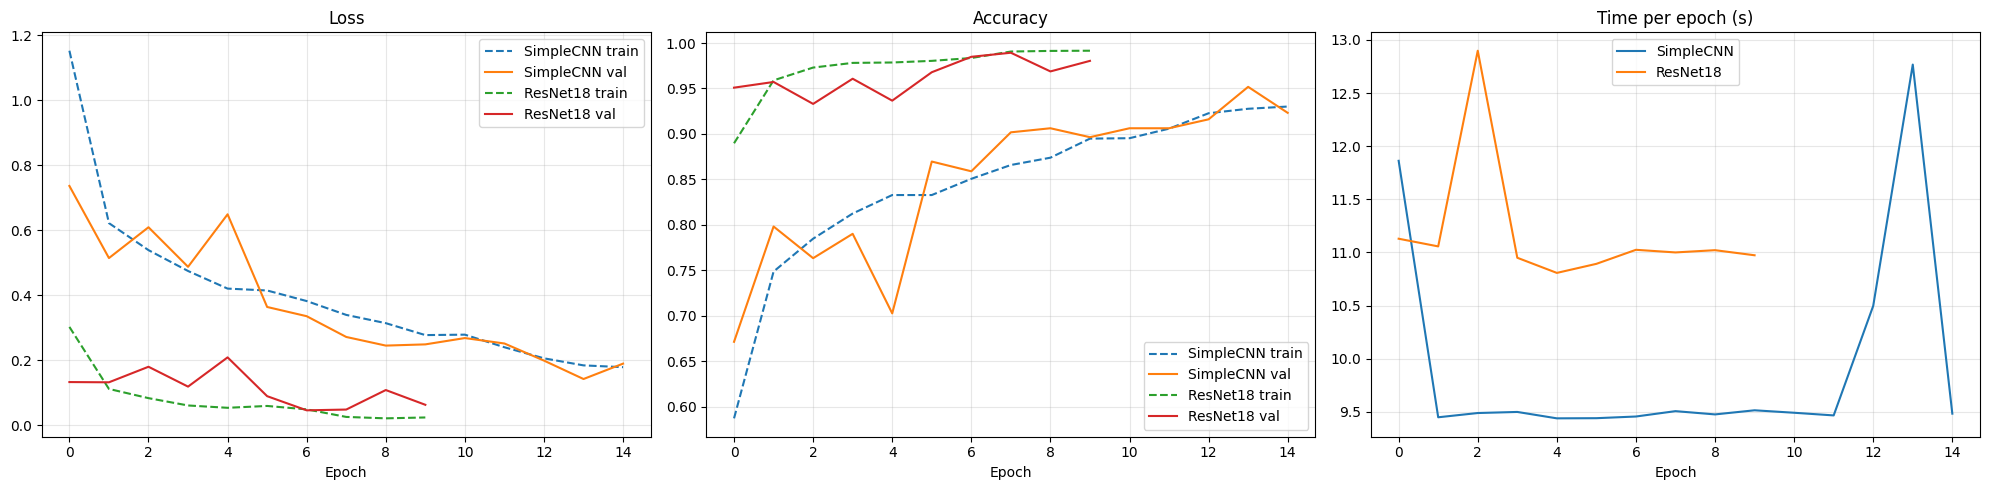

In [15]:
def plot_histories(histories):
    fig, axes = plt.subplots(1, 3, figsize=(20, 5))
    for name, h in histories.items():
        axes[0].plot(h["train_loss"], "--", label=f"{name} train")
        axes[0].plot(h["val_loss"],   "-",  label=f"{name} val")
        axes[1].plot(h["train_acc"],  "--", label=f"{name} train")
        axes[1].plot(h["val_acc"],    "-",  label=f"{name} val")
        axes[2].plot(h["time"],       "-",  label=f"{name}")
    axes[0].set_title("Loss");     axes[0].set_xlabel("Epoch"); axes[0].grid(alpha=0.3)
    axes[1].set_title("Accuracy"); axes[1].set_xlabel("Epoch"); axes[1].grid(alpha=0.3)
    axes[2].set_title("Time per epoch (s)"); axes[2].set_xlabel("Epoch"); axes[2].grid(alpha=0.3)
    for ax in axes: ax.legend()
    plt.tight_layout(); plt.show()

plot_histories({"SimpleCNN": hist_cnn, "ResNet18": hist_resnet})

**Вывод по кривым обучения:**
- ResNet18 сходится с первой эпохи (val acc ~95%, val loss ~0.13). SimpleCNN, обучаясь с нуля,
  достигает 92–95% только к 14-й эпохе.
- У SimpleCNN кривые train и val идут рядом (~93% и 92–95%): переобучения нет, модель скорее
  недообучена, её можно обучать дольше.
- У ResNet train accuracy ~99%, а val колеблется между 93% и 99%: заметна лёгкая нестабильность.
- Скачки val loss связаны с небольшим размером val (1120 снимков) и случайностью аугментаций.
- ResNet остановилась на 10-й эпохе: лучший val loss был на 7-й, дальше 3 эпохи (patience=3)
  улучшения не было, и вернулись веса 7-й эпохи.
- Время эпохи: ~10 с у SimpleCNN и ~11 с у ResNet. Пики на графике времени это случайные
  задержки Colab.

Оценка на тесте


SimpleCNN — Test Accuracy: 0.8900
              precision    recall  f1-score   support

      glioma     0.9643    0.7425    0.8390       400
  meningioma     0.8770    0.8375    0.8568       400
     notumor     0.7956    0.9925    0.8832       400
   pituitary     0.9611    0.9875    0.9741       400

    accuracy                         0.8900      1600
   macro avg     0.8995    0.8900    0.8883      1600
weighted avg     0.8995    0.8900    0.8883      1600



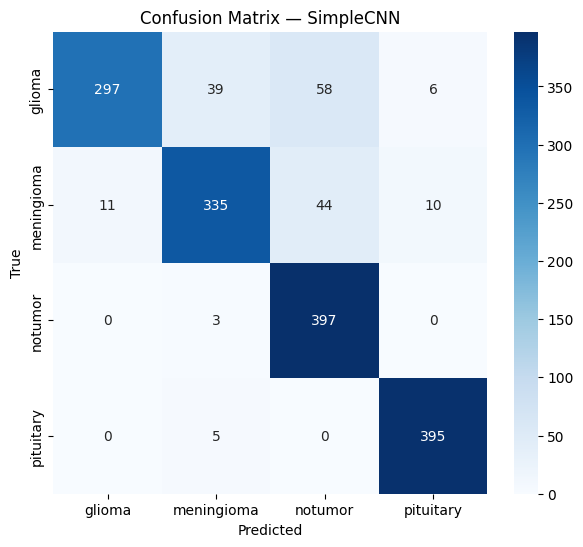


ResNet18 — Test Accuracy: 0.9387
              precision    recall  f1-score   support

      glioma     1.0000    0.7975    0.8873       400
  meningioma     0.8974    0.9625    0.9288       400
     notumor     0.8969    1.0000    0.9456       400
   pituitary     0.9803    0.9950    0.9876       400

    accuracy                         0.9387      1600
   macro avg     0.9436    0.9387    0.9373      1600
weighted avg     0.9436    0.9387    0.9373      1600



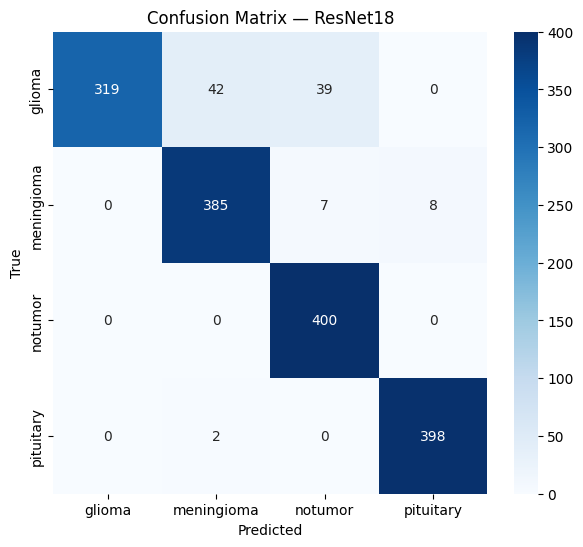

In [16]:
def full_report(model, loader, title):
    criterion = nn.CrossEntropyLoss()
    _, acc, y_true, y_pred = evaluate(model, loader, criterion)
    print(f"\n{'='*60}\n{title} — Test Accuracy: {acc:.4f}\n{'='*60}")
    print(classification_report(y_true, y_pred,
                                target_names=class_names, digits=4))
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(7, 6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names, yticklabels=class_names)
    plt.xlabel("Predicted"); plt.ylabel("True")
    plt.title(f"Confusion Matrix — {title}")
    plt.show()
    return {"acc": acc, "y_true": y_true, "y_pred": y_pred}

res_cnn    = full_report(cnn_model,    test_loader, "SimpleCNN")
res_resnet = full_report(resnet_model, test_loader, "ResNet18")

**Вывод по матрицам ошибок и отчётам:**
- Test accuracy: SimpleCNN 0.890, ResNet18 0.939.
- Обе модели хуже всего находят glioma: recall 0.74 (CNN) и 0.80 (ResNet).
  Из 400 glioma CNN верно нашла 297 (39 приняла за meningioma, 58 за notumor),
  ResNet нашла 319 (42 -> meningioma, 39 -> notumor).
- Самая опасная ошибка в медицине это пропуск опухоли (glioma -> notumor).
- Классы notumor и pituitary распознаются почти идеально (ResNet: 400/400 и 398/400).
- У notumor recall высокий (0.99 и 1.0), но precision ниже (0.80 и 0.90): модели склонны
  называть снимок "без опухоли".
- Precision показывает, какая доля предсказаний класса верна, recall показывает, какую долю
  настоящих снимков класса нашли. Для медицины важнее recall по опасным классам.

Сводная таблица

In [17]:
def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def summarize(name, hist, res, model):
    p, r, f, _ = precision_recall_fscore_support(
        res["y_true"], res["y_pred"], average="macro", zero_division=0
    )
    return {
        "Model": name,
        "Params": f"{count_params(model):,}",
        "Best val acc": f"{max(hist['val_acc']):.4f}",
        "Test acc":     f"{res['acc']:.4f}",
        "Macro precision": f"{p:.4f}",
        "Macro recall":    f"{r:.4f}",
        "Macro F1":        f"{f:.4f}",
        "Mean epoch time (s)": f"{np.mean(hist['time']):.1f}",
        "Epochs trained": len(hist["time"]),
    }

df_cmp = pd.DataFrame([
    summarize("SimpleCNN", hist_cnn,    res_cnn,    cnn_model),
    summarize("ResNet18",  hist_resnet, res_resnet, resnet_model),
]).set_index("Model")
df_cmp

,Params,Best val acc,Test acc,Macro precision,Macro recall,Macro F1,Mean epoch time (s),Epochs trained
Model,,,,,,,,
SimpleCNN,"2,339,972",0.9518,0.8900,0.8995,0.8900,0.8883,9.9,15
ResNet18,"11,178,564",0.9893,0.9387,0.9436,0.9387,0.9373,11.2,10


**Вывод по таблице:**
ResNet18 лучше по всем метрикам качества (test acc 0.939 против 0.890,
macro F1 0.937 против 0.888). Платой стали параметры: 11.2 млн против 2.3 млн.  Время эпохи при этом почти одинаковое (~11 с и ~10 с на GPU T4)

Примеры предсказаний

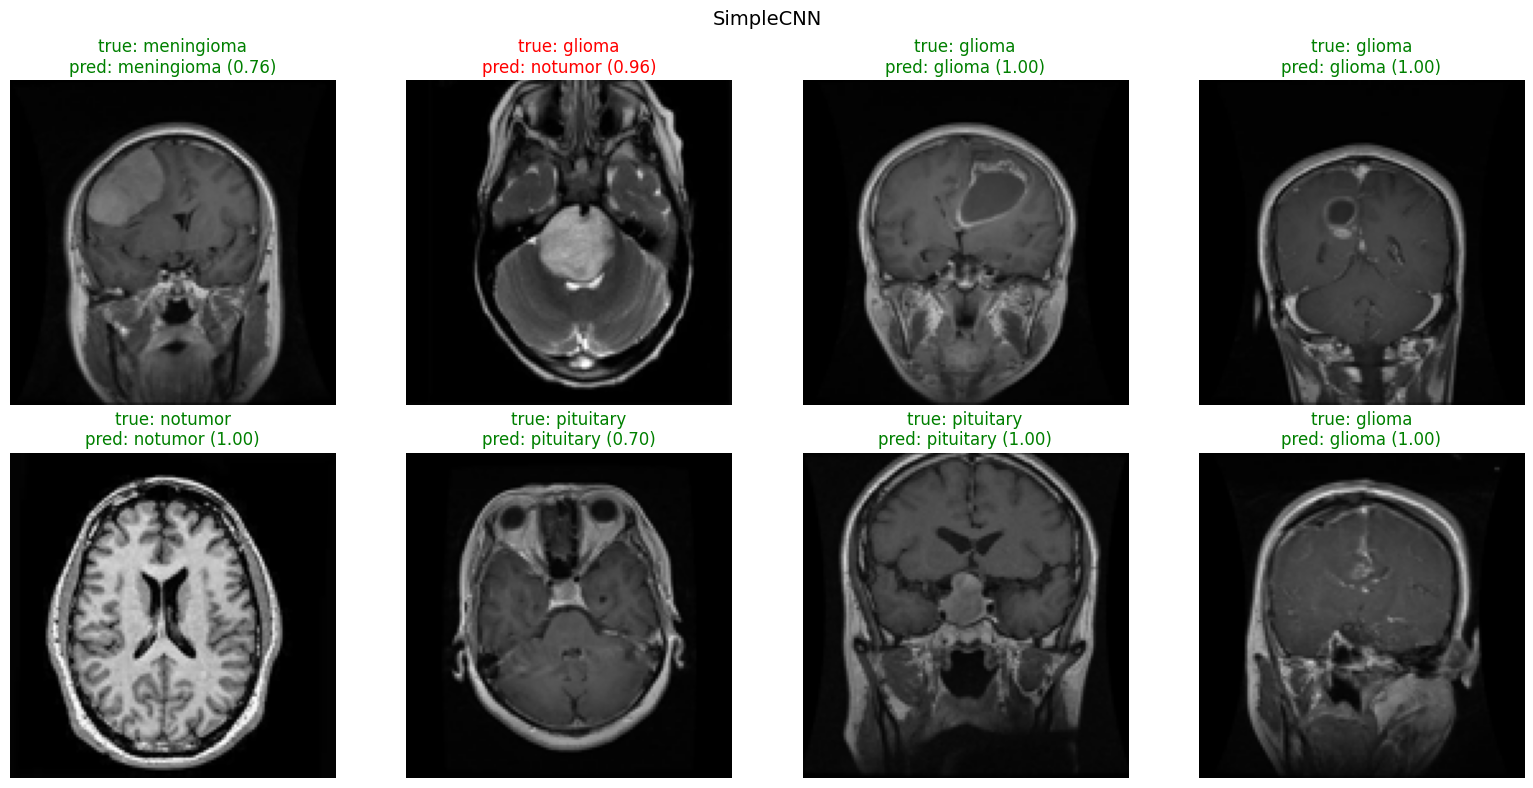

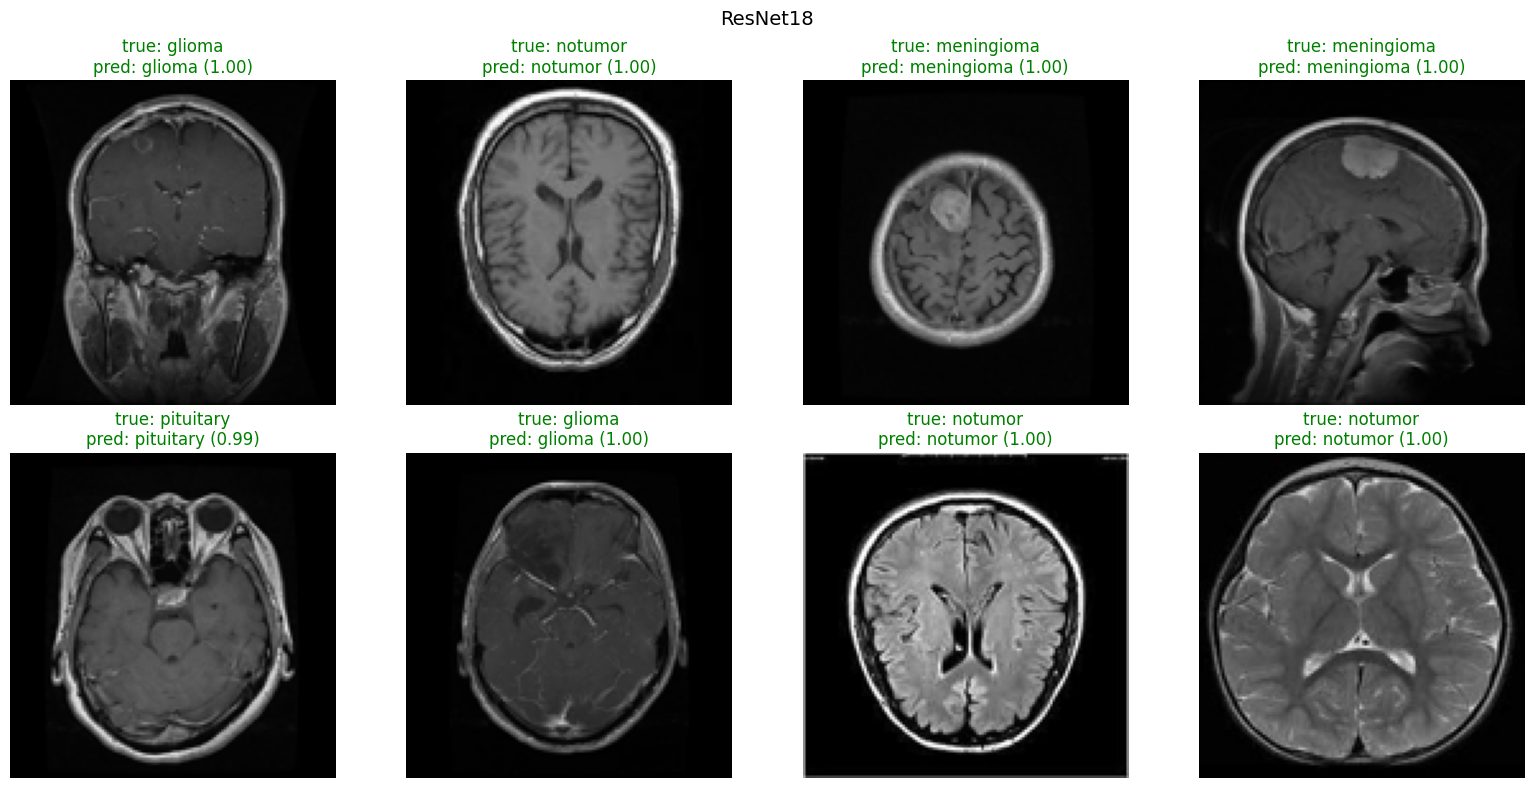

In [18]:
@torch.no_grad()
def show_predictions(model, images, labels, n=8, title="Model"):
    model.eval()
    idxs = np.random.choice(len(images), n, replace=False)
    fig, axes = plt.subplots(2, n // 2, figsize=(16, 8))
    for ax, i in zip(axes.ravel(), idxs):
        tensor = eval_tfms(images[i]).unsqueeze(0).to(device)
        prob = torch.softmax(model(tensor), dim=1).cpu().numpy().ravel()
        pred = int(np.argmax(prob))
        ax.imshow(images[i])
        color = "green" if pred == labels[i] else "red"
        ax.set_title(f"true: {class_names[labels[i]]}\n"
                     f"pred: {class_names[pred]} ({prob[pred]:.2f})",
                     color=color)
        ax.axis("off")
    plt.suptitle(title, fontsize=14)
    plt.tight_layout(); plt.show()

show_predictions(cnn_model,    X_test, y_test_enc, n=8, title="SimpleCNN")
show_predictions(resnet_model, X_test, y_test_enc, n=8, title="ResNet18")

**Вывод по примерам:** зелёный заголовок значит, что модель угадала, красный значит, что
ошиблась. В скобках уверенность модели (вероятность после softmax). Ошибки (если есть
красные) чаще всего приходятся на glioma, что согласуется с матрицами ошибок.

**Ограничения работы:**
- Val выбран из того же набора, что и train, поэтому val accuracy (0.95 у CNN и 0.99 у ResNet)
  выше, чем test (0.89 и 0.94). Честной оценкой считаю test.
- Результаты получены за один запуск. Без нескольких запусков с разными seed нельзя точно
  сказать, насколько устойчива разница ~5% между моделями.
- Метрики на test не стоит переносить на реальную клиническую практику: это учебная работа
  на открытом датасете.

## Итоги и что улучшить:

**Результаты на тесте (1600 снимков, 4 класса):**

| Модель | Параметров | Test acc | Macro F1 | Время эпохи |
|---|---|---|---|---|
| SimpleCNN | 2.34 млн | 0.890 | 0.888 | ~9.9 с |
| ResNet18 (pretrained) | 11.18 млн | 0.939 | 0.937 | ~11.2 с |

- **ResNet18 выигрывает** примерно на 5 процентных пунктов accuracy. Предобученные на ImageNet признаки помогли: уже после 1-й эпохи val accuracy ~95%, а SimpleCNN, обучаясь с нуля, достигла такого уровня только к 14-й эпохе.
- **Выигрывает**: параметров примерно в 4.8 раза больше, а время эпохи почти такое же (~11 против ~10 с на GPU T4).
- **Переобучение**: у SimpleCNN train и val близки (~93% и 92–95%), то есть модель скорее недообучена, можно обучать дольше. У ResNet train accuracy ~99%, а val колеблется (93–99%), заметна некоторая нестабильность.
- **Разрыв между val и test**: val accuracy 0.95 (CNN) и 0.99 (ResNet), а test 0.89 и 0.94. Val-выборка взята из того же набора, что и train, а test это отдельный набор, поэтому на нём качество ниже. Честной оценкой считаю test.
- **Ошибки**: обе модели хуже всего находят glioma (recall 0.74 у CNN, 0.80 у ResNet). Их принимают за meningioma и за notumor. Опасный тип ошибки: пропуск опухоли (glioma → notumor). Pituitary и notumor распознаются почти идеально.

**Что можно улучшить:**
- обучать SimpleCNN дольше и подобрать архитектуру глубже;
- для ResNet использовать планировщик (CosineAnnealing) и больше аугментаций;
- взвесить классы или оптимизировать recall для glioma;
- попробовать другие предобученные модели (ResNet50, EfficientNet);
- использовать Grad-CAM, чтобы посмотреть, на какие области снимка смотрит модель;
- обучать на снимках большего размера (сейчас 128×128).